# CG for Sparse Least Squares

Solve
$$\min_{\mathbf{x}}\ \frac12\|\mathbf{B}\mathbf{x}-\mathbf{b}\|_2^2+\frac{\lambda}{2}\|\mathbf{x}\|_2^2,$$
where $\mathbf{B}\in\mathbb{R}^{m\times n}$ is sparse and $m=2n$.
Complete the `TODO` sections and run cells in order. Keep all function interfaces unchanged.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import random as sparse_random
from scipy.linalg import cho_factor, cho_solve

## 1. Data and direct solver (provided)
Each trial generates new data, shared by both methods. The default nonzero fraction is $20/n$, giving about 20 nonzeros per row on average. The direct method forms the dense normal-equation matrix and uses Cholesky factorization.

In [2]:
def generate_data(n, seed, density=None):
    """Return sparse B (2*n, n) and observations b (2*n,).
    density is the fraction of nonzero entries (e.g., 0.01 means 1%).
    """
    rng = np.random.default_rng(seed)
    if density is None:
        density = min(20 / n, 1.0)
    B = sparse_random(
        2*n, n, density=density, format="csr",
        random_state=rng, data_rvs=rng.standard_normal
    ) / np.sqrt(n * density)
    x_true = rng.standard_normal(n)
    b = B @ x_true + 0.01 * rng.standard_normal(2*n)
    return B, b


def direct_solve(B, b, lam):
    """Return the solution vector x, shape (n,)."""
    A = (B.T @ B).toarray(order="F")
    A.flat[::A.shape[0] + 1] += lam
    c = B.T @ b
    factor = cho_factor(A, lower=True, overwrite_a=True, check_finite=False)
    return cho_solve(factor, c, check_finite=False)


def relative_residual(B, b, lam, x):
    """Return the explicitly recomputed relative normal-equation residual."""
    r = B.T @ (B @ x - b) + lam * x
    return np.linalg.norm(r) / np.linalg.norm(B.T @ b)

## 2. Matrix-vector product and CG
Implement `matvec(B, v, lam)` to compute $(\mathbf{B}^\top\mathbf{B}+\lambda\mathbf{I})\mathbf{v}$ without forming $\mathbf{B}^\top\mathbf{B}$.

Implement practical CG (slide 46) to solve $\mathbf{A}\mathbf{x}=\mathbf{b}$ for symmetric positive definite $\mathbf{A}$, starting from $\mathbf{x}_0=\mathbf{0}$. Here `cg` receives a function `matvec(v)` computing $\mathbf{A}\mathbf{v}$, rather than the matrix $\mathbf{A}$ itself.

Use $\mathbf{r}_k=\mathbf{A}\mathbf{x}_k-\mathbf{b}$ and stop when $\|\mathbf{r}_k\|_2\le\epsilon\|\mathbf{b}\|_2$ or at the iteration limit. If the initial residual satisfies the stopping criterion, return immediately with zero iterations.

In [7]:
def matvec(B, v, lam):
    """Inputs: sparse B (m,n), vector v (n,), scalar lam > 0.
    Output: vector (B.T @ B + lam*I) @ v, shape (n,).
    """
    v = (B.T @ (B @ v)) + lam * v
    return v


def cg(matvec, b, epsilon=1e-8, maxiter=2000):
    """Inputs: callable matvec(v) returning A @ v, vector b (n,),
    relative tolerance epsilon, and integer iteration limit maxiter.
    Outputs: solution x (n,) and integer iteration count.
    The matrix A is symmetric positive definite.
    """
    norm_b = np.linalg.norm(b)
    if norm_b == 0:
        return np.zeros_like(b), 0

    x = np.zeros_like(b)
    r = b.copy()
    p = r.copy()
    
    r_dot_r = np.dot(r, r)
    stop_tol = (epsilon * norm_b) ** 2

    if r_dot_r < stop_tol:
        return x, 0

    for k in range(maxiter):
        Ap = matvec(p)
        alpha = r_dot_r / np.dot(p, Ap)
        x = x + alpha * p
        r = r - alpha * Ap

        r_dot_r_next = np.dot(r, r)
        if r_dot_r_next < stop_tol:
            return x, k + 1

        beta = r_dot_r_next / r_dot_r
        p = r + beta * p
        r_dot_r = r_dot_r_next

    return x, maxiter

## 3. Experiments
For each dimension, generate five independent random problems and compare CG with dense Cholesky ($n\le10000$). Timing includes solver setup and excludes data generation and residual checks.

Include the completed $\texttt{matvec}$, $\texttt{cg}$, and $\texttt{run\_cg}$ functions, and the timing plot from the final cell . 
The printed table is for checking the computations.

The final plot is saved as `cg_vs_cholesky.pdf` in the current working directory.

In [8]:
sizes = [500, 1000, 2000, 10000, 50000]
seeds = [42, 43, 44, 45, 46]
direct_limit = 10000

lam = 0.01
epsilon = 1e-8
maxiter = 2000

In [12]:
def run_cg(B, b, lam, epsilon, maxiter):
    """Return the CG solution and iteration count for this least-squares problem."""
    mv = lambda v: matvec(B, v, lam)
    rhs = B.T @ b
    return cg(mv, rhs, epsilon=epsilon, maxiter=maxiter)

In [14]:
# Warm up both solvers outside the timed experiments.
B0, b0 = generate_data(100, seed=0)
run_cg(B0, b0, lam, epsilon, maxiter)
direct_solve(B0, b0, lam)

results = []
print("Times: mean ± SD; iterations and residuals: means")
print(f"{'(m, n)':>16} | {'CG time (s)':>17} | {'Direct time (s)':>17} | "
      f"{'CG iter':>7} | {'CG residual':>11} | {'Direct residual':>15}")

for n in sizes:
    times = {"CG": [], "Direct": []}
    residuals = {"CG": [], "Direct": []}
    iterations = []
    for trial, seed in enumerate(seeds):
        B, b = generate_data(n, seed)
        methods = ["CG", "Direct"] if n <= direct_limit else ["CG"]
        if trial % 2:
            methods.reverse()
        for method in methods:
            start = time.perf_counter()
            if method == "CG":
                x, steps = run_cg(B, b, lam, epsilon, maxiter)
            else:
                x = direct_solve(B, b, lam)
            times[method].append(time.perf_counter() - start)
            residuals[method].append(relative_residual(B, b, lam, x))
            if method == "CG":
                iterations.append(steps)

    row = {"n": n}
    for method in ["CG", "Direct"]:
        values = times[method]
        row[method] = (np.mean(values), np.std(values, ddof=1)) if values else None
    results.append(row)
    cg_text = f"{row['CG'][0]:.3f} ± {row['CG'][1]:.3f}"
    direct_text, direct_res = "-", "-"
    if row["Direct"] is not None:
        direct_text = f"{row['Direct'][0]:.3f} ± {row['Direct'][1]:.3f}"
        direct_res = f"{np.mean(residuals['Direct']):.2e}"
    print(f"{str((2*n, n)):>16} | {cg_text:>17} | {direct_text:>17} | "
          f"{np.mean(iterations):7.1f} | {np.mean(residuals['CG']):11.2e} | "
          f"{direct_res:>15}")
    failed = sum(r > epsilon for r in residuals["CG"])
    if failed:
        print(f"  CG residual exceeded tolerance in {failed}/{len(seeds)} trials.")

Times: mean ± SD; iterations and residuals: means
          (m, n) |       CG time (s) |   Direct time (s) | CG iter | CG residual | Direct residual
     (1000, 500) |     0.002 ± 0.000 |     0.005 ± 0.000 |    50.8 |    8.69e-09 |        5.04e-16
    (2000, 1000) |     0.003 ± 0.001 |     0.013 ± 0.001 |    52.0 |    9.19e-09 |        5.92e-16
    (4000, 2000) |     0.007 ± 0.001 |     0.039 ± 0.006 |    53.0 |    8.98e-09 |        7.54e-16
  (20000, 10000) |     0.061 ± 0.026 |     1.582 ± 0.123 |    55.0 |    8.28e-09 |        1.49e-15
 (100000, 50000) |     0.470 ± 0.083 |                 - |    57.0 |    8.87e-09 |               -


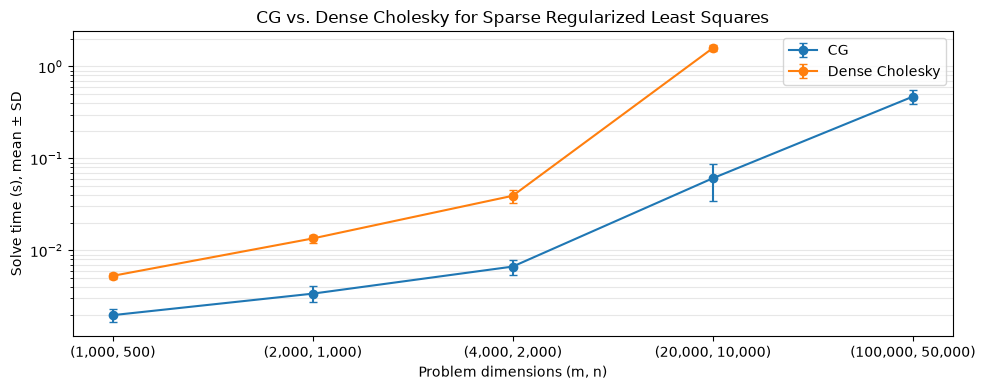

In [15]:
plt.figure(figsize=(10, 4))
for method in ["CG", "Direct"]:
    indices = [i for i, row in enumerate(results) if row[method] is not None]
    means = [results[i][method][0] for i in indices]
    stds = [results[i][method][1] for i in indices]
    plt.errorbar(indices, means, yerr=stds, fmt="o-", capsize=3,
                 label="CG" if method == "CG" else "Dense Cholesky")
plt.xticks(range(len(sizes)), [f"({2*n:,}, {n:,})" for n in sizes])
plt.yscale("log")
plt.xlabel("Problem dimensions (m, n)")
plt.ylabel("Solve time (s), mean ± SD")
plt.title("CG vs. Dense Cholesky for Sparse Regularized Least Squares")
plt.grid(True, axis="y", which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("cg_vs_cholesky.pdf", bbox_inches="tight")
plt.show()